## 1. Paths and setup

In [1]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
VIDEO_DIR = PROJECT_DIR / "data" / "raw" / "grid"
ALIGN_DIR = VIDEO_DIR / "alignments"

SPEAKER = "s1"

print(PROJECT_DIR)
print(VIDEO_DIR.exists())
print(ALIGN_DIR.exists())

c:\Users\vova1\Documents\vscodefiles\resume projects\Speech recognition
True
True


## 2. Dataset overview

In [2]:
videos = sorted(VIDEO_DIR.rglob("*.mpg"))
aligns = sorted(ALIGN_DIR.rglob("*.align"))

print("videos:", len(videos))
print("aligns:", len(aligns))

videos: 4000
aligns: 34000


In [3]:
def make_key(path):
    speaker = path.parent.name
    name = path.stem
    return speaker + "/" + name

video_speakers = set()
for path in videos:
    video_speakers.add(path.parent.name)
print("Video speakers:", sorted(video_speakers))

Video speakers: ['s1', 's2', 's3', 's4']


In [4]:
video_keys = set()
for path in videos:
    video_keys.add(make_key(path))

align_keys = set()
for path in aligns:
    align_keys.add(make_key(path))

missing = video_keys - align_keys
print("Videos without alignments:", len(missing))

Videos without alignments: 0


In [5]:
first_align = aligns[0]
text = first_align.read_text()
print(first_align.name)
print(text)

bbaf2n.align
0 23750 sil
23750 29500 bin
29500 34000 blue
34000 35500 at
35500 41000 f
41000 47250 two
47250 53000 now
53000 74500 sil



In [6]:
from collections import Counter
word_counter = Counter()

for path in aligns:
    text = path.read_text()
    lines = text.splitlines()

    for line in lines:
        parts = line.split()
        word = parts[2]
        word_counter[word] += 1

print("Unique words:", len(word_counter))
print()

for word, count in word_counter.most_common():
    print(word, count)

Unique words: 53

sil 68000
lay 8665
place 8536
at 8508
in 8504
blue 8500
now 8500
soon 8500
please 8500
again 8500
green 8500
red 8500
white 8500
by 8496
with 8492
bin 8455
set 8344
two 3400
three 3400
four 3400
five 3400
six 3400
seven 3400
eight 3400
nine 3400
one 3400
zero 3400
sp 2931
f 1360
l 1360
s 1360
z 1360
m 1360
e 1360
r 1360
g 1360
t 1360
a 1360
h 1360
n 1360
u 1360
b 1360
o 1360
i 1360
d 1360
k 1360
q 1360
x 1360
y 1360
j 1360
c 1360
p 1360
v 1360


## 4. Read labels

In [7]:
SKIP_WORDS = ["sil", "sp"]


def read_align(path):
    text = path.read_text()
    lines = text.splitlines()

    words = []
    for line in lines:
        parts = line.split()
        word = parts[2]

        if word in SKIP_WORDS:
            continue

        words.append(word)

    sentence = " ".join(words)
    return sentence

check

In [8]:
for path in aligns[:5]:
    sentence = read_align(path)
    print(path.name, "->", sentence)

bbaf2n.align -> bin blue at f two now
bbaf3s.align -> bin blue at f three soon
bbaf4p.align -> bin blue at f four please
bbaf5a.align -> bin blue at f five again
bbal6n.align -> bin blue at l six now


In [9]:
for path in aligns:
    text = path.read_text()
    tokens = text.split()

    if "sp" in tokens:
        print(path.name)
        print(text)
        print("->", read_align(path))
        break

bbiz2p.align
0 16750 sil
16750 22000 bin
22000 28500 blue
28500 30750 in
30750 35000 z
35000 35750 sp
35750 41000 two
41000 52250 please
52250 74500 sil

-> bin blue in z two please


In [10]:
bad_files = []

for path in aligns:
    sentence = read_align(path)
    words = sentence.split()

    if len(words) != 6:
        bad_files.append(path)

print("Files checked:", len(aligns))
print("Files without 6 words:", len(bad_files))

Files checked: 34000
Files without 6 words: 0


## 5. Read video

In [11]:
import cv2


def read_video(path):
    capture = cv2.VideoCapture(str(path))
    frames = []

    while True:
        success, frame = capture.read()

        if not success:
            break

        frames.append(frame)

    capture.release()
    return frames


frames = read_video(videos[0])

print("Video:", videos[0].name)
print("Number of frames:", len(frames))
print("Frame shape:", frames[0].shape)

Video: bbaf2n.mpg
Number of frames: 75
Frame shape: (288, 360, 3)


In [12]:
from collections import Counter

frame_counter = Counter()
bad_videos = []

for path in videos:
    frames = read_video(path)
    number_of_frames = len(frames)
    frame_counter[number_of_frames] += 1

    if number_of_frames != 75:
        bad_videos.append(path)

print("Frames per video:", frame_counter.most_common())
print("Videos without 75 frames:", len(bad_videos))

Frames per video: [(75, 3986), (74, 13), (72, 1)]
Videos without 75 frames: 14


In [13]:
print("Bad videos:")
for path in bad_videos:
    print(make_key(path))

clean_videos = []
for path in videos:
    if path not in bad_videos:
        clean_videos.append(path)

print()
print("All videos:", len(videos))
print("Removed:", len(bad_videos))
print("Clean videos:", len(clean_videos))

Bad videos:
s1/lrae3s
s1/sbbbzp
s1/srbb4n
s1/srwi5a
s1/swao7a
s3/sbaa4p
s3/sbim8p
s3/sgwp8p
s4/bbaf2a
s4/lbad5p
s4/lwirzs
s4/pwbx5n
s4/pwbx6s
s4/swah7n

All videos: 4000
Removed: 14
Clean videos: 3986


## 6. Look at one frame

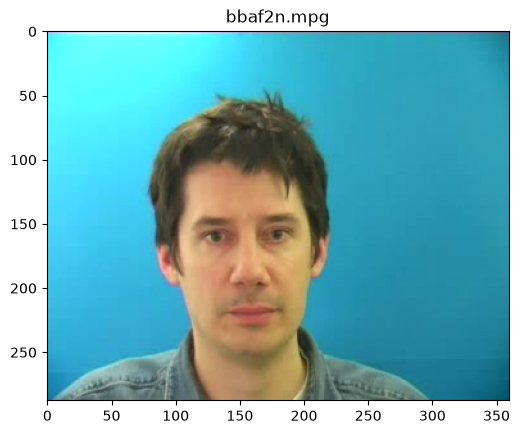

In [14]:
import matplotlib.pyplot as plt

frames = read_video(clean_videos[0])
first_frame = frames[0]

rgb_frame = cv2.cvtColor(first_frame, cv2.COLOR_BGR2RGB)

plt.imshow(rgb_frame)
plt.title(clean_videos[0].name)
plt.show()

## 7. Find the mouth

In [15]:
import mediapipe as mp

face_mesh = mp.solutions.face_mesh.FaceMesh(
    static_image_mode=True,
    max_num_faces=1,
)

results = face_mesh.process(rgb_frame)
landmarks = results.multi_face_landmarks[0].landmark

print("Number of face points:", len(landmarks))
print("First point:", landmarks[0])

Number of face points: 468
First point: x: 0.443445623
y: 0.748373866
z: -0.029506322



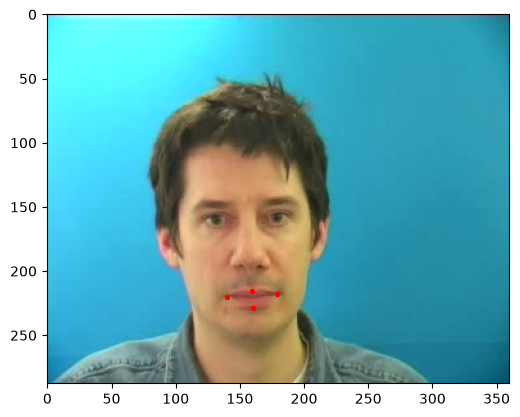

In [16]:
LIP_POINTS = [61, 291, 0, 17]

height = rgb_frame.shape[0]
width = rgb_frame.shape[1]

plt.imshow(rgb_frame)

for index in LIP_POINTS:
    point = landmarks[index]
    x = point.x * width
    y = point.y * height
    plt.scatter(x, y, color="red", s=8)

plt.show()

## 8. Crop the mouth

In [17]:
def get_mouth_center(landmarks, width, height):
    xs = []
    ys = []

    for index in LIP_POINTS:
        point = landmarks[index]
        xs.append(point.x * width)
        ys.append(point.y * height)

    center_x = int(sum(xs) / len(xs))
    center_y = int(sum(ys) / len(ys))
    return center_x, center_y


center_x, center_y = get_mouth_center(landmarks, width, height)
print("Mouth center:", center_x, center_y)

Mouth center: 159 220


Mouth shape: (40, 80, 3)


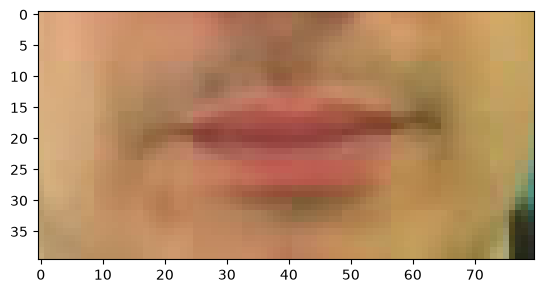

In [18]:
CROP_WIDTH = 80
CROP_HEIGHT = 40

left = center_x - CROP_WIDTH // 2
right = center_x + CROP_WIDTH // 2
top = center_y - CROP_HEIGHT // 2
bottom = center_y + CROP_HEIGHT // 2

mouth = rgb_frame[top:bottom, left:right]

print("Mouth shape:", mouth.shape)
plt.imshow(mouth)
plt.show()

## 9. Crop mouth on every frame

In [19]:
MOUTH_WIDTH = 80
MOUTH_HEIGHT = 40
SCALE = 2.0


def crop_mouth(rgb_frame, landmarks):
    height = rgb_frame.shape[0]
    width = rgb_frame.shape[1]

    left_corner = landmarks[61]
    right_corner = landmarks[291]
    mouth_size = (right_corner.x - left_corner.x) * width

    crop_width = int(mouth_size * SCALE)
    crop_height = crop_width // 2

    center_x, center_y = get_mouth_center(landmarks, width, height)

    left = center_x - crop_width // 2
    right = left + crop_width
    top = center_y - crop_height // 2
    bottom = top + crop_height

    mouth = rgb_frame[top:bottom, left:right]
    mouth = cv2.resize(mouth, (MOUTH_WIDTH, MOUTH_HEIGHT))
    return mouth

In [20]:
import time


def crop_video(path):
    frames = read_video(path)

    face_mesh = mp.solutions.face_mesh.FaceMesh(
        static_image_mode=False,
        max_num_faces=1,
    )

    mouths = []
    for frame in frames:
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = face_mesh.process(rgb_frame)

        if results.multi_face_landmarks is None:
            face_mesh.close()
            return None

        landmarks = results.multi_face_landmarks[0].landmark
        mouth = crop_mouth(rgb_frame, landmarks)
        mouths.append(mouth)

    face_mesh.close()
    return mouths


start = time.time()
mouths = crop_video(clean_videos[0])
seconds = time.time() - start

print("Frames:", len(mouths))
print("Mouth shape:", mouths[0].shape)
print("Seconds for one video:", round(seconds, 2))

Frames: 75
Mouth shape: (40, 80, 3)
Seconds for one video: 0.27


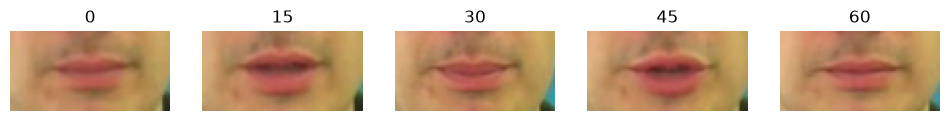

In [21]:
frame_numbers = [0, 15, 30, 45, 60]

fig, axes = plt.subplots(1, 5, figsize=(12, 2))

for i, frame_number in enumerate(frame_numbers):
    axes[i].imshow(mouths[frame_number])
    axes[i].set_title(frame_number)
    axes[i].axis("off")

plt.show()

## 10. Save mouth crops

In [23]:
import numpy as np

OUTPUT_DIR = PROJECT_DIR / "data" / "processed" / "grid"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


def get_output_path(video_path):
    speaker = video_path.parent.name
    file_name = video_path.stem + ".npy"
    return OUTPUT_DIR / speaker / file_name


def save_mouths(video_path):
    mouths = crop_video(video_path)

    if mouths is None:
        return False

    gray_mouths = []
    for mouth in mouths:
        gray = cv2.cvtColor(mouth, cv2.COLOR_RGB2GRAY)
        gray_mouths.append(gray)

    array = np.array(gray_mouths)

    output_path = get_output_path(video_path)
    output_path.parent.mkdir(exist_ok=True)
    np.save(output_path, array)
    return True

save_mouths(clean_videos[0])

test_array = np.load(get_output_path(clean_videos[0]))
print("Saved shape:", test_array.shape)

Saved shape: (75, 40, 80)


In [24]:
from tqdm import tqdm

failed_videos = []

for video_path in tqdm(clean_videos):
    output_path = get_output_path(video_path)

    if output_path.exists():
        continue

    success = save_mouths(video_path)

    if not success:
        failed_videos.append(video_path)

print("Failed videos:", len(failed_videos))

100%|██████████| 3986/3986 [18:02<00:00,  3.68it/s]

Failed videos: 26


## 11. Failed videos

In [25]:
failed_counter = Counter()

for path in failed_videos:
    speaker = path.parent.name
    failed_counter[speaker] += 1

print(failed_counter)

Counter({'s1': 11, 's3': 11, 's2': 3, 's4': 1})


In [26]:
def find_missing_face_frames(path):
    frames = read_video(path)

    face_mesh = mp.solutions.face_mesh.FaceMesh(
        static_image_mode=True,
        max_num_faces=1,
    )

    missing_frames = []
    for frame_number, frame in enumerate(frames):
        rgb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        results = face_mesh.process(rgb_frame)

        if results.multi_face_landmarks is None:
            missing_frames.append(frame_number)

    face_mesh.close()
    return missing_frames


for path in failed_videos[:5]:
    missing = find_missing_face_frames(path)
    print(make_key(path), "-> frames without face:", missing)

s1/bbizzn -> frames without face: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
s1/brwa4p -> frames without face: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
s1/brwg8p -> frames without face: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
s1/bwwuzn -> frames without face: [0, 1, 2, 3, 4, 5, 6, 7]
s1/lgbf8n -> frames without face: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


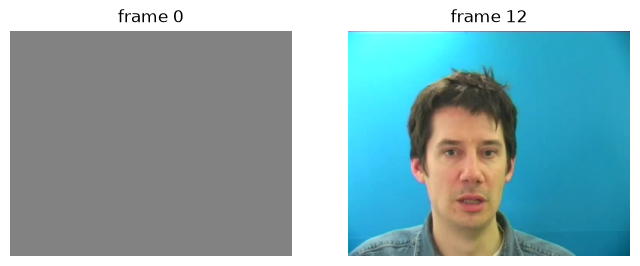

In [27]:
bad_video = failed_videos[0]
frames = read_video(bad_video)

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

for i, frame_number in enumerate([0, 12]):
    rgb_frame = cv2.cvtColor(frames[frame_number], cv2.COLOR_BGR2RGB)
    axes[i].imshow(rgb_frame)
    axes[i].set_title("frame " + str(frame_number))
    axes[i].axis("off")

plt.show()

In [28]:
saved_files = sorted(OUTPUT_DIR.rglob("*.npy"))
print("Saved files:", len(saved_files))

Saved files: 3960


In [30]:
import pandas as pd

rows = []

for npy_path in saved_files:
    speaker = npy_path.parent.name
    name = npy_path.stem

    align_path = ALIGN_DIR / speaker / (name + ".align")
    sentence = read_align(align_path)

    row = {"speaker": speaker, "name": name, "sentence": sentence}
    rows.append(row)

labels = pd.DataFrame(rows)
labels.to_csv(OUTPUT_DIR / "labels.csv", index=False)

print(labels.head())


  speaker    name                   sentence
0      s1  bbaf2n      bin blue at f two now
1      s1  bbaf3s   bin blue at f three soon
2      s1  bbaf4p  bin blue at f four please
3      s1  bbaf5a   bin blue at f five again
4      s1  bbal6n      bin blue at l six now


In [31]:
print(labels["speaker"].value_counts())

speaker
s2    997
s4    993
s3    986
s1    984
Name: count, dtype: int64
